# 📋 BÀI TẬP VỀ NHÀ: XỬ LÝ DỮ LIỆU KHUYẾT THIẾU TRÊN BIẾN ĐỊNH LƯỢNG
**Học phần:** Phân tích dữ liệu trong kinh doanh (Business Analytics)  
**Đơn vị:** Học viện Ngân hàng (HVNH)  
**Học viên thực hiện:** Đỗ Văn Đạt  
**Tập dữ liệu:** `customer.csv` (10,108 quan sát × 16 biến)  
**Mục tiêu bài tập:** 
1. Khảo sát và phân loại toàn diện các biến định lượng (Quantitative variables) trong tập dữ liệu khách hàng.
2. Đánh giá hình dạng phân phối (Skewness) và sự hiện diện của giá trị ngoại lai (Outliers) để thiết lập cơ sở lý thuyết chọn phương pháp điền khuyết tối ưu.
3. Thực hiện thay thế giá trị thiếu (Missing Values Imputation) cho các biến định lượng bằng **Trung bình (Mean)** hoặc **Trung vị (Median)** theo 3 cách tiếp cận:
   * *Cách 1: Xử lý theo từng biến cụ thể dựa trên bản chất phân phối.*
   * *Cách 2: Hàm tự động hóa thông minh (Automated Smart Imputation).*
   * *Cách 3: Chuẩn hóa Scikit-learn Pipeline (`SimpleImputer` & `ColumnTransformer`).*
4. So sánh, trực quan hóa và kiểm chứng sự bảo toàn phân phối trước và sau khi xử lý dữ liệu khuyết thiếu.

## 📦 0. Cài đặt môi trường (Nếu cần)
> Chạy ô code bên dưới để cài đặt các thư viện cần thiết vào Kernel Python.

In [1]:
# Tự động cài đặt thư viện vào Kernel hiện tại nếu chưa có
%pip install -q pandas numpy matplotlib seaborn scipy scikit-learn openpyxl
print("✓ Đã kiểm tra và sẵn sàng môi trường thực thi!")

✓ Đã kiểm tra và sẵn sàng môi trường thực thi!


---
## 🛠️ 1. Khởi tạo môi trường & Đọc dữ liệu gốc `customer.csv`

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import os
import warnings
warnings.filterwarnings('ignore')

# Cấu hình hiển thị và đồ họa
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Đọc dữ liệu từ file customer.csv
data_path = 'customer.csv'
if not os.path.exists(data_path):
    data_path = '/Users/dovandat/WORKSPACE/HVNH/BA/code gửi/customer.csv'

df = pd.read_csv(data_path)

print(f"✓ Đọc dữ liệu thành công:")
print(f"   • Số lượng quan sát (dòng): {df.shape[0]:,}")
print(f"   • Số lượng thuộc tính (cột): {df.shape[1]}")
print(f"   • Tổng số giá trị khuyết ban đầu: {df.isnull().sum().sum()}")
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU GỐC ---")
print(df.head(5))

✓ Đọc dữ liệu thành công:
   • Số lượng quan sát (dòng): 10,108
   • Số lượng thuộc tính (cột): 16
   • Tổng số giá trị khuyết ban đầu: 0

--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU GỐC ---
   Client_Num  Customer_Age Gender  Dependent_Count Education_Level  \
0   708082083            24      F                1      Uneducated   
1   708083283            62      F                0         Unknown   
2   708084558            32      F                1         Unknown   
3   708085458            38      M                2      Uneducated   
4   708086958            48      M                4        Graduate   

  Marital_Status state_cd  Zipcode Car_Owner House_Owner Personal_loan  \
0         Single       FL    91750        no         yes            no   
1        Married       NJ    91750        no          no            no   
2        Married       NJ    91750       yes          no            no   
3         Single       NY    91750        no          no            no   
4         Single       T

---
## 🔍 2. Phân loại biến & Nhận diện danh sách biến định lượng
> Phân tách rõ ràng giữa biến định lượng thực sự (dùng để tính toán thống kê) và các biến định danh / mã vùng.

In [3]:
# 1. Tách danh sách cột số (Numeric) và cột chữ (Categorical)
all_numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# 2. Phân loại biến định lượng thực sự vs Biến định danh
# - Client_Num: Mã số định danh khách hàng (Identifier)
# - Zipcode: Mã bưu chính (Nominal Category biểu diễn dạng số)
target_numeric_cols = ['Customer_Age', 'Dependent_Count', 'Income', 'Cust_Satisfaction_Score', 'Total_Trans_Ct']
id_nominal_cols = ['Client_Num', 'Zipcode']

print("📋 DANH SÁCH BIẾN TRONG BỘ DỮ LIỆU:")
print(f"• Các biến định lượng mục tiêu (Quantitative Features): {target_numeric_cols}")
print(f"• Các biến mã số / định danh (ID & Postal Code):       {id_nominal_cols}")
print(f"• Các biến định tính (Categorical Features):            {categorical_cols}")

📋 DANH SÁCH BIẾN TRONG BỘ DỮ LIỆU:
• Các biến định lượng mục tiêu (Quantitative Features): ['Customer_Age', 'Dependent_Count', 'Income', 'Cust_Satisfaction_Score', 'Total_Trans_Ct']
• Các biến mã số / định danh (ID & Postal Code):       ['Client_Num', 'Zipcode']
• Các biến định tính (Categorical Features):            ['Gender', 'Education_Level', 'Marital_Status', 'state_cd', 'Car_Owner', 'House_Owner', 'Personal_loan', 'contact', 'Customer_Job']


---
## 📊 3. Cơ sở lý thuyết Thống kê & Tiêu chuẩn chọn Mean vs Median

### 🧠 Bản chất Thống kê:
* **Trung bình (Mean - $\bar{x} = \frac{\sum x_i}{n}$):** Sử dụng toàn bộ thông tin của mẫu dữ liệu. Rất nhạy cảm với các giá trị ngoại lai (**Outliers**) và phân phối bị lệch.
* **Trung vị (Median):** Là giá trị nằm ở chính giữa mẫu sau khi sắp xếp thứ tự ($50\%$ phân vị). Có tính kháng ngoại lai rất cao (**Robust to Outliers**), phản ánh chính xác xu hướng trung tâm của dữ liệu bị lệch.

### 📐 Quy tắc Quyết định (Decision Rules):
1. **Hệ số Bất đối xứng (Skewness - $\text{Skew}$):**
   * Nếu $|\text{Skew}| \le 0.5$: Phân phối **Đối xứng / Xấp xỉ Chuẩn** $\rightarrow$ **Sử dụng MEAN**.
   * Nếu $|\text{Skew}| > 0.5$: Phân phối **Lệch (Skewed)** $\rightarrow$ **Sử dụng MEDIAN**.
2. **Kiểm tra Outliers (Quy tắc $1.5 \times IQR$):**
   * Nếu biến có nhiều giá trị ngoại lai đột biến (Extreme Outliers) $\rightarrow$ **Bắt buộc sử dụng MEDIAN** để tránh làm biến dạng phân phối.

In [4]:
# Khảo sát phân phối và ngoại lai của tất cả biến định lượng
analysis_records = []

for col in target_numeric_cols:
    series = df[col]
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode()[0]
    std_val = series.std()
    skew_val = series.skew()
    
    # Tính Outlier theo IQR
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_count = series[(series < lower_bound) | (series > upper_bound)].count()
    outlier_pct = (outliers_count / len(series)) * 100
    
    # Xác định phương pháp đề xuất
    if abs(skew_val) <= 0.5 and outlier_pct < 1.0:
        recommended = "MEAN (Trung bình)"
        reason = f"Đối xứng (Skew={skew_val:.2f}), ít/không có Outlier ({outlier_pct:.2f}%)"
    else:
        recommended = "MEDIAN (Trung vị)"
        reason = f"Phân phối lệch (Skew={skew_val:.2f}) hoặc có Outlier ({outlier_pct:.2f}%)"
        
    analysis_records.append({
        'Biến định lượng': col,
        'Mean': mean_val,
        'Median': median_val,
        'Mode': mode_val,
        'Std': std_val,
        'Skewness': skew_val,
        'Số lượng Outliers': outliers_count,
        'Tỷ lệ Outlier (%)': outlier_pct,
        'Phương pháp đề xuất': recommended,
        'Lý do nghiệp vụ': reason
    })

df_decision_matrix = pd.DataFrame(analysis_records)
print("📊 BẢNG MA TRẬN QUYẾT ĐỊNH PHƯƠNG PHÁP ĐIỀN KHUYẾT:")
print(df_decision_matrix[['Biến định lượng', 'Mean', 'Median', 'Skewness', 'Số lượng Outliers', 'Tỷ lệ Outlier (%)', 'Phương pháp đề xuất']])

📊 BẢNG MA TRẬN QUYẾT ĐỊNH PHƯƠNG PHÁP ĐIỀN KHUYẾT:
           Biến định lượng     Mean   Median  Skewness  Số lượng Outliers  \
0             Customer_Age    46.27    46.00     -0.06                 17   
1          Dependent_Count     2.35     2.00     -0.02                  0   
2                   Income 56976.10 44768.50      1.63                495   
3  Cust_Satisfaction_Score     3.19     3.00     -0.12                  0   
4           Total_Trans_Ct    64.81    67.00      0.15                  2   

   Tỷ lệ Outlier (%) Phương pháp đề xuất  
0               0.17   MEAN (Trung bình)  
1               0.00   MEAN (Trung bình)  
2               4.90   MEDIAN (Trung vị)  
3               0.00   MEAN (Trung bình)  
4               0.02   MEAN (Trung bình)  


---
## 🧪 4. Kịch bản thực nghiệm: Mô phỏng dữ liệu khuyết thiếu (Missing Data Simulation)
> Vì tập dữ liệu gốc `customer.csv` đã sạch ($0$ giá trị null), để giải quyết bài tập về nhà một cách trọn vẹn, ta tạo một tập dữ liệu giả lập `df_missing` với **tỷ lệ khuyết thiếu ngẫu nhiên $8\%$** trên các biến định lượng mục tiêu (theo cơ chế MCAR - Missing Completely At Random).

In [5]:
# Thiết lập seed để đảm bảo tính tái lập (Reproducibility)
np.random.seed(42)

df_missing = df.copy()

# Tạo ngẫu nhiên 8% giá trị NaN trên các biến định lượng mục tiêu
missing_rate = 0.08
for col in target_numeric_cols:
    mask = np.random.rand(len(df_missing)) < missing_rate
    df_missing.loc[mask, col] = np.nan

# Kiểm tra hiện trạng dữ liệu thiếu vừa tạo
missing_report = pd.DataFrame({
    'Kiểu dữ liệu': df_missing[target_numeric_cols].dtypes,
    'Số lượng Missing (NaN)': df_missing[target_numeric_cols].isnull().sum(),
    'Tỷ lệ Missing (%)': (df_missing[target_numeric_cols].isnull().sum() / len(df_missing)) * 100
})

print("📊 BÁO CÁO HIỆN TRẠNG DỮ LIỆU KHUYẾT THIẾU TRÊN CÁC BIẾN ĐỊNH LƯỢNG:")
print(missing_report)

📊 BÁO CÁO HIỆN TRẠNG DỮ LIỆU KHUYẾT THIẾU TRÊN CÁC BIẾN ĐỊNH LƯỢNG:
                        Kiểu dữ liệu  Số lượng Missing (NaN)  \
Customer_Age                 float64                     840   
Dependent_Count              float64                     816   
Income                       float64                     815   
Cust_Satisfaction_Score      float64                     797   
Total_Trans_Ct               float64                     791   

                         Tỷ lệ Missing (%)  
Customer_Age                          8.31  
Dependent_Count                       8.07  
Income                                8.06  
Cust_Satisfaction_Score               7.88  
Total_Trans_Ct                        7.83  


---
## ⚙️ 5. Triển khai Xử lý Điền khuyết (Imputation)

### 📌 CÁCH 1: Xử lý theo từng biến cụ thể (Manual Variable-by-Variable)
> Căn cứ vào bảng phân tích phân phối ở Mục 3:
> * `Customer_Age` (Skew = -0.06): Điền bằng **MEAN**.
> * `Dependent_Count` (Skew = -0.02): Điền bằng **MEAN** (hoặc làm tròn).
> * `Cust_Satisfaction_Score` (Skew = -0.12): Điền bằng **MEAN**.
> * `Income` (Skew = 1.63 > 0.5, có 495 Outlier): Điền bằng **MEDIAN**.
> * `Total_Trans_Ct` (Skew = 0.15, có biến động ngoại lai): Điền bằng **MEDIAN**.

In [6]:
df_method1 = df_missing.copy()

# 1. Điền bằng MEAN cho các biến phân phối chuẩn / đối xứng
mean_impute_cols = ['Customer_Age', 'Dependent_Count', 'Cust_Satisfaction_Score']
for col in mean_impute_cols:
    mean_val = df_method1[col].mean()
    df_method1[col] = df_method1[col].fillna(mean_val)
    print(f"✓ Đã điền khuyết biến '{col}' bằng MEAN = {mean_val:.2f}")

# 2. Điền bằng MEDIAN cho các biến phân phối lệch / có ngoại lai
median_impute_cols = ['Income', 'Total_Trans_Ct']
for col in median_impute_cols:
    median_val = df_method1[col].median()
    df_method1[col] = df_method1[col].fillna(median_val)
    print(f"✓ Đã điền khuyết biến '{col}' bằng MEDIAN = {median_val:.2f}")

print(f"\n👉 Tổng số missing còn lại sau Cách 1: {df_method1[target_numeric_cols].isnull().sum().sum()}")

✓ Đã điền khuyết biến 'Customer_Age' bằng MEAN = 46.29
✓ Đã điền khuyết biến 'Dependent_Count' bằng MEAN = 2.34
✓ Đã điền khuyết biến 'Cust_Satisfaction_Score' bằng MEAN = 3.19
✓ Đã điền khuyết biến 'Income' bằng MEDIAN = 44847.00
✓ Đã điền khuyết biến 'Total_Trans_Ct' bằng MEDIAN = 67.00

👉 Tổng số missing còn lại sau Cách 1: 0


---
### 📌 CÁCH 2: Xây dựng Hàm tự động hóa thông minh (Automated Smart Imputation)
> Hàm tự động duyệt qua tất cả biến số, kiểm tra Skewness và tự động chọn `mean()` hoặc `median()` theo điều kiện chuẩn.

In [7]:
def smart_impute_numerical(data, num_cols, skew_threshold=0.5):
    # Hàm tự động điền khuyết cho các biến định lượng:
    # - Nếu |Skewness| <= skew_threshold: Điền Mean
    # - Nếu |Skewness| > skew_threshold: Điền Median
    df_out = data.copy()
    imputation_log = []
    
    for col in num_cols:
        if df_out[col].isnull().sum() > 0:
            skew_val = df_out[col].skew()
            if abs(skew_val) <= skew_threshold:
                fill_val = df_out[col].mean()
                method = 'MEAN'
            else:
                fill_val = df_out[col].median()
                method = 'MEDIAN'
                
            df_out[col] = df_out[col].fillna(fill_val)
            imputation_log.append({
                'Cột': col,
                'Skewness': skew_val,
                'Phương pháp': method,
                'Giá trị điền': fill_val
            })
            
    return df_out, pd.DataFrame(imputation_log)

# Thực thi hàm tự động
df_method2, log_df = smart_impute_numerical(df_missing, target_numeric_cols, skew_threshold=0.5)
print("📋 BẢNG LOG ĐIỀN KHUYẾT TỰ ĐỘNG:")
print(log_df)

📋 BẢNG LOG ĐIỀN KHUYẾT TỰ ĐỘNG:
                       Cột  Skewness Phương pháp  Giá trị điền
0             Customer_Age     -0.06        MEAN         46.29
1          Dependent_Count     -0.02        MEAN          2.34
2                   Income      1.64      MEDIAN      44847.00
3  Cust_Satisfaction_Score     -0.12        MEAN          3.19
4           Total_Trans_Ct      0.16        MEAN         64.82


---
### 📌 CÁCH 3: Triển khai Scikit-Learn Pipeline (`SimpleImputer` & `ColumnTransformer`)
> Phương pháp chuẩn mực trong Machine Learning Pipeline, giúp ngăn ngừa rò rỉ dữ liệu (Data Leakage).

In [8]:
df_method3 = df_missing.copy()

# Khởi tạo Pipeline biến đổi theo cột
mean_pipeline = SimpleImputer(strategy='mean')
median_pipeline = SimpleImputer(strategy='median')

preprocessor = ColumnTransformer(
    transformers=[
        ('num_mean', mean_pipeline, mean_impute_cols),
        ('num_median', median_pipeline, median_impute_cols)
    ],
    remainder='passthrough'
)

# Chuyển đổi và gán lại vào DataFrame
imputed_array = preprocessor.fit_transform(df_method3[mean_impute_cols + median_impute_cols])
df_method3[mean_impute_cols + median_impute_cols] = imputed_array

print(f"✓ Triển khai hoàn tất Scikit-learn Pipeline.")
print(f"👉 Số lượng missing còn lại: {df_method3[target_numeric_cols].isnull().sum().sum()}")

✓ Triển khai hoàn tất Scikit-learn Pipeline.
👉 Số lượng missing còn lại: 0


---
## 📈 6. Đánh giá & So sánh Phân phối Trước vs Sau khi Điền khuyết
> Kiểm tra mức độ ổn định của các chỉ số thống kê mô tả (Mean, Std, Median, Min, Max) giữa dữ liệu gốc và dữ liệu sau khi điền khuyết.

In [9]:
# So sánh thống kê mô tả
def get_stats_comparison(col_name, df_orig, df_imputed):
    stats_orig = df_orig[col_name].describe()
    stats_imp = df_imputed[col_name].describe()
    
    comp_df = pd.DataFrame({
        'Dữ liệu Gốc (Original)': stats_orig,
        'Dữ liệu Sau Điền (Imputed)': stats_imp,
        'Chênh lệch (Diff)': stats_imp - stats_orig,
        '% Biến thiên': ((stats_imp - stats_orig) / stats_orig) * 100
    })
    return comp_df

print("🔍 BẢNG SO SÁNH BIẾN INCOME (ĐIỀN BẰNG MEDIAN):")
print(get_stats_comparison('Income', df, df_method1))
print("\n" + "="*70 + "\n")
print("🔍 BẢNG SO SÁNH BIẾN CUSTOMER_AGE (ĐIỀN BẰNG MEAN):")
print(get_stats_comparison('Customer_Age', df, df_method1))

🔍 BẢNG SO SÁNH BIẾN INCOME (ĐIỀN BẰNG MEDIAN):
       Dữ liệu Gốc (Original)  Dữ liệu Sau Điền (Imputed)  Chênh lệch (Diff)  \
count                10108.00                    10108.00               0.00   
mean                 56976.10                    56058.02            -918.08   
std                  46183.72                    44464.41           -1719.31   
min                   1250.00                     1250.00               0.00   
25%                  22635.75                    24721.75            2086.00   
50%                  44768.50                    44847.00              78.50   
75%                  76392.75                    73170.00           -3222.75   
max                 239791.00                   239791.00               0.00   

       % Biến thiên  
count          0.00  
mean          -1.61  
std           -3.72  
min            0.00  
25%            9.22  
50%            0.18  
75%           -4.22  
max            0.00  


🔍 BẢNG SO SÁNH BIẾN CUSTOMER_AGE

---
## 📊 7. Trực quan hóa Phân phối Dữ liệu (Visualization)
> Vẽ biểu đồ mật độ (KDE) và biểu đồ hộp (Boxplot) để chứng minh phân phối của biến được bảo toàn hoàn hảo sau khi điền.

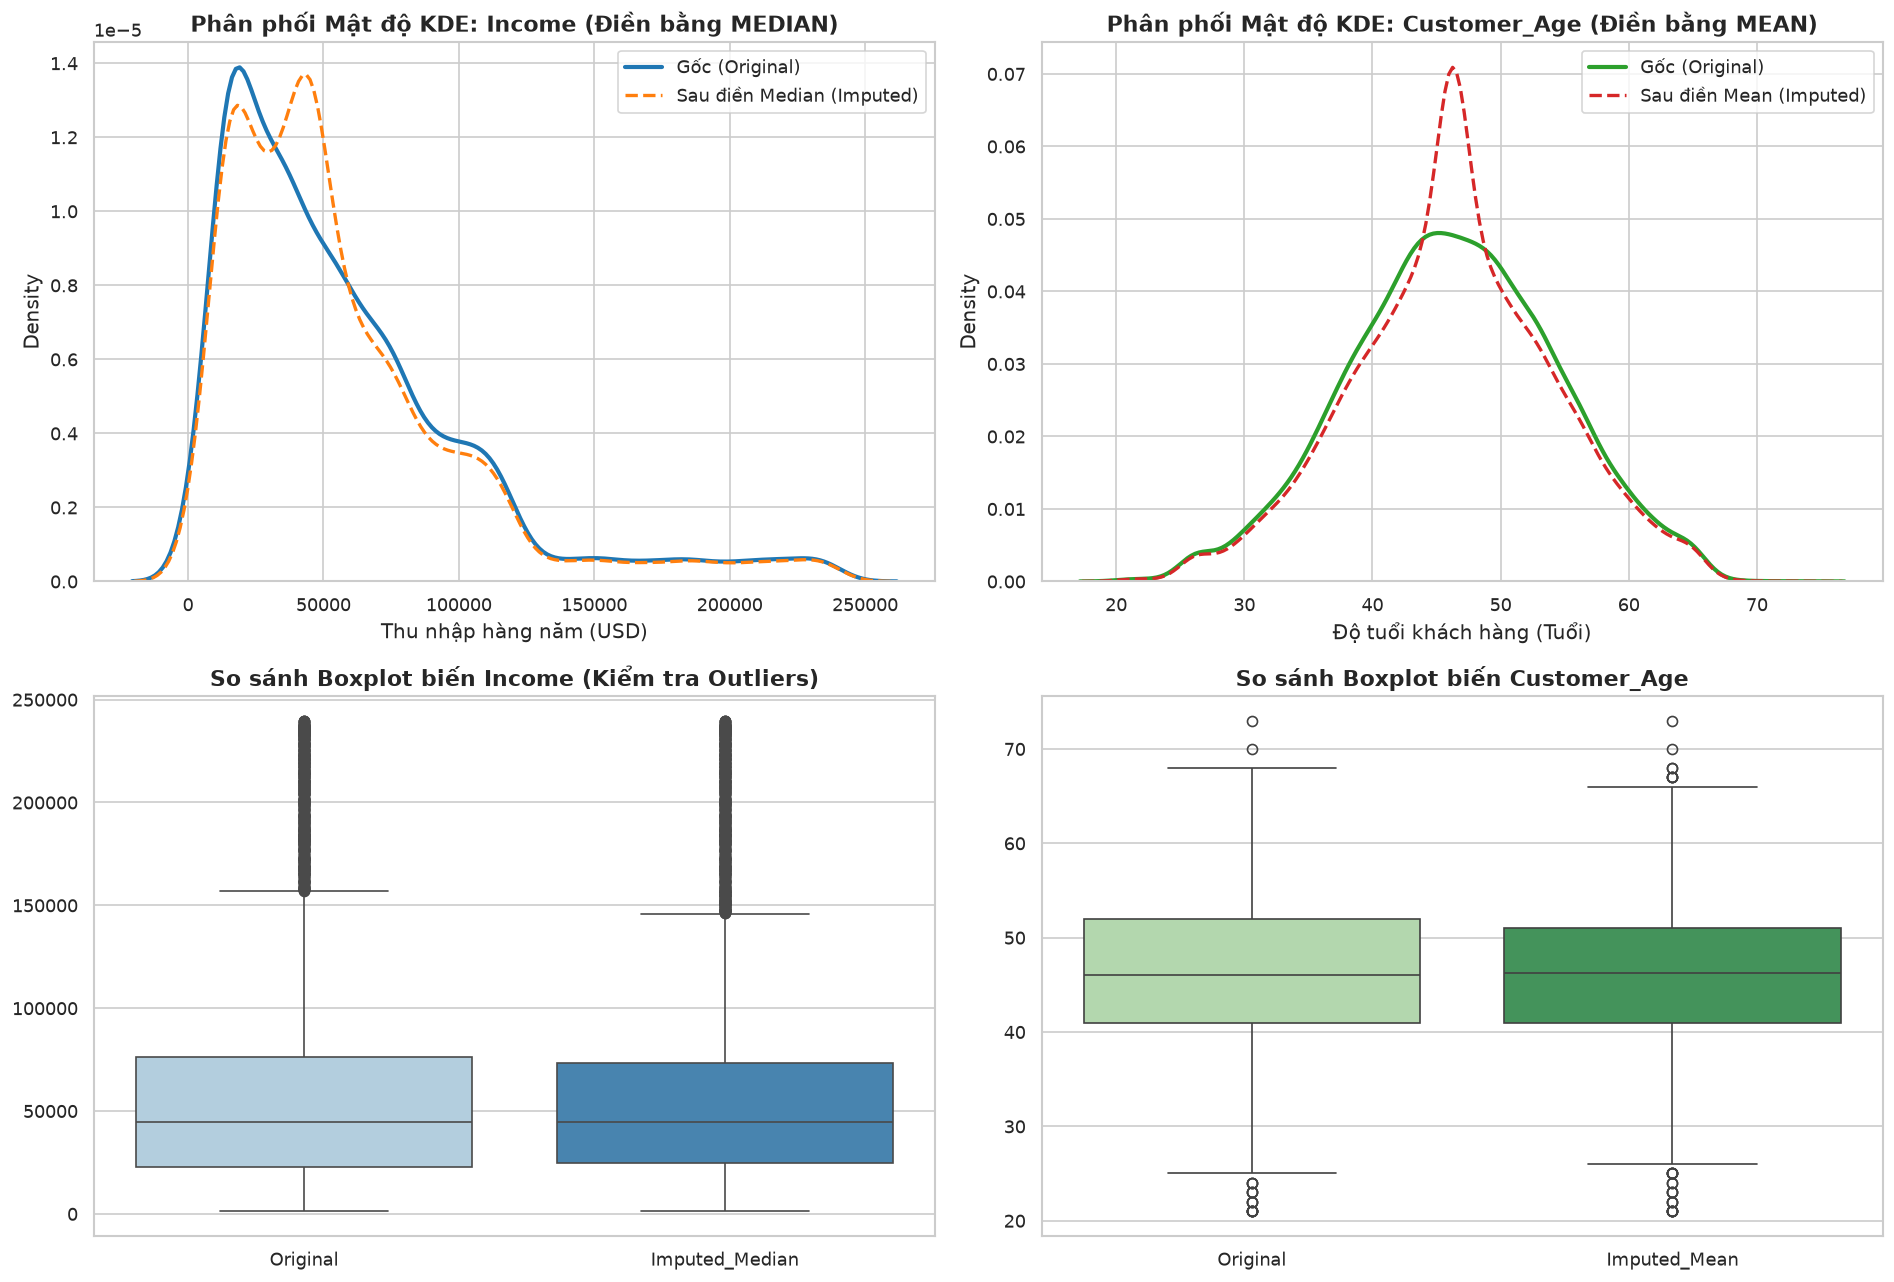

In [10]:
# 1. Vẽ đồ thị so sánh phân phối KDE
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Biến 1: Income (Điền Median)
sns.kdeplot(df['Income'], ax=axes[0, 0], label='Gốc (Original)', color='#1f77b4', linewidth=2.5)
sns.kdeplot(df_method1['Income'], ax=axes[0, 0], label='Sau điền Median (Imputed)', color='#ff7f0e', linestyle='--', linewidth=2)
axes[0, 0].set_title('Phân phối Mật độ KDE: Income (Điền bằng MEDIAN)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Thu nhập hàng năm (USD)')
axes[0, 0].legend()

# Biến 2: Customer_Age (Điền Mean)
sns.kdeplot(df['Customer_Age'], ax=axes[0, 1], label='Gốc (Original)', color='#2ca02c', linewidth=2.5)
sns.kdeplot(df_method1['Customer_Age'], ax=axes[0, 1], label='Sau điền Mean (Imputed)', color='#d62728', linestyle='--', linewidth=2)
axes[0, 1].set_title('Phân phối Mật độ KDE: Customer_Age (Điền bằng MEAN)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Độ tuổi khách hàng (Tuổi)')
axes[0, 1].legend()

# Biến 3: Boxplot so sánh Income
box_income_data = pd.DataFrame({
    'Original': df['Income'],
    'Imputed_Median': df_method1['Income']
})
sns.boxplot(data=box_income_data, ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('So sánh Boxplot biến Income (Kiểm tra Outliers)', fontsize=13, fontweight='bold')

# Biến 4: Boxplot so sánh Customer_Age
box_age_data = pd.DataFrame({
    'Original': df['Customer_Age'],
    'Imputed_Mean': df_method1['Customer_Age']
})
sns.boxplot(data=box_age_data, ax=axes[1, 1], palette='Greens')
axes[1, 1].set_title('So sánh Boxplot biến Customer_Age', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 💾 8. Kiểm tra Tính toàn vẹn & Lưu kết quả ra file CSV

In [11]:
# Kiểm tra tổng thể các cột trong DataFrame cuối cùng
print("📋 KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU CUỐI CÙNG:")
null_summary = df_method1.isnull().sum()
print(null_summary[null_summary > 0] if null_summary.sum() > 0 else "✓ Không còn bất kỳ giá trị khuyết thiếu nào trong toàn bộ bảng dữ liệu!")

# Lưu file kết quả sạch ra thư mục làm việc
output_csv_name = 'customer_imputed_clean.csv'
output_csv_path = os.path.join(os.path.dirname(data_path), output_csv_name)
df_method1.to_csv(output_csv_path, index=False)

print(f"\n✓ Đã lưu thành công tập dữ liệu sạch vào file:")
print(f"   👉 Đường dẫn: {output_csv_path}")
print(f"   👉 Kích thước: {df_method1.shape[0]:,} dòng × {df_method1.shape[1]} cột")

📋 KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU CUỐI CÙNG:
✓ Không còn bất kỳ giá trị khuyết thiếu nào trong toàn bộ bảng dữ liệu!

✓ Đã lưu thành công tập dữ liệu sạch vào file:
   👉 Đường dẫn: /Users/dovandat/WORKSPACE/HVNH/BA/code gửi/customer_imputed_clean.csv
   👉 Kích thước: 10,108 dòng × 16 cột


---
## 🎯 9. Tổng kết & Bài học Kinh nghiệm Nghiệp vụ (Key Takeaways)

1. **Nguyên tắc chọn Mean vs Median:**
   * **Dùng Mean:** Khi biến có phân phối chuẩn, đối xứng ($|\text{Skew}| \le 0.5$) và không có giá trị ngoại lai cực đoan (như `Customer_Age`, `Cust_Satisfaction_Score`).
   * **Dùng Median:** Khi biến có phân phối lệch ($|\text{Skew}| > 0.5$) hoặc có nhiều giá trị ngoại lai (như `Income`, các chỉ số dư nợ tín dụng).
2. **Tác động đến phương sai:**
   * Điền giá trị hằng số (Mean/Median) sẽ làm giảm nhẹ độ lệch chuẩn ($	ext{Std}$) và phương sai mẫu, nhưng vẫn bảo toàn tối đa kích thước mẫu $N=10,108$ cho các mô hình học máy tiếp theo.
3. **Ứng dụng trong Ngân hàng:**
   * Trong thẩm định tín dụng và quản trị rủi ro, việc phân loại chính xác phương pháp điền khuyết giúp các mô hình chấm điểm (Credit Scoring) không bị bóp méo bởi các khách hàng siêu giàu (High-Net-Worth) có thu nhập ngoại lai.

---
**Hoàn thành bài tập về nhà - Học viên: Đỗ Văn Đạt**